# 01 — Análise exploratória e tratamento dos dados

Duas bases do [Anime Recommendation Database 2020](https://www.kaggle.com/datasets/hernan4444/anime-recommendation-database-2020):

- `anime.csv`: uma linha por anime, com as características usadas na **clusterização** (Modelo 1);
- `rating_complete.csv`: uma linha por nota de usuário, usada na **filtragem colaborativa** (Modelo 2).

Este notebook explora as duas, decide o que entra nos modelos e salva os dados tratados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from joblib import dump
from scipy import sparse

from src.auxiliares import extrair_ano, faixa_de_ano, montar_features, tamanho
from src.config import (
    ANIMES_FEATURES,
    ANIMES_TRATADOS,
    DADOS_ANIMES,
    DADOS_AVALIACOES,
    DADOS_SINOPSES,
    MATRIZ_USUARIO_ANIME,
    MIN_AVALIACOES_ANIME,
    MIN_AVALIACOES_USUARIO,
    N_USUARIOS,
    RANDOM_STATE,
)
from src.graficos import AZUL, barras_horizontais, configurar_estilo

configurar_estilo()

## 1. Base de animes

In [2]:
animes = pd.read_csv(DADOS_ANIMES)
print(animes.shape)
animes.head(3)

(17562, 35)


,MAL_ID,Name,Score,Genres,English name,Japanese name,Type,Episodes,Aired,Premiered,...,Score-10,Score-9,Score-8,Score-7,Score-6,Score-5,Score-4,Score-3,Score-2,Score-1
0,1,Cowboy Bebop,8.78,"Action, Adventure, Comedy, Drama, Sci-Fi, Space",Cowboy Bebop,カウボーイビバップ,TV,26,"Apr 3, 1998 to Apr 24, 1999",Spring 1998,...,229170.0,182126.0,131625.0,62330.0,20688.0,8904.0,3184.0,1357.0,741.0,1580.0
1,5,Cowboy Bebop: Tengoku no Tobira,8.39,"Action, Drama, Mystery, Sci-Fi, Space",Cowboy Bebop:The Movie,カウボーイビバップ 天国の扉,Movie,1,"Sep 1, 2001",Unknown,...,30043.0,49201.0,49505.0,22632.0,5805.0,1877.0,577.0,221.0,109.0,379.0
2,6,Trigun,8.24,"Action, Sci-Fi, Adventure, Comedy, Drama, Shounen",Trigun,トライガン,TV,26,"Apr 1, 1998 to Sep 30, 1998",Spring 1998,...,50229.0,75651.0,86142.0,49432.0,15376.0,5838.0,1965.0,664.0,316.0,533.0


Os valores ausentes vêm escritos como `"Unknown"`, não como `NaN`.

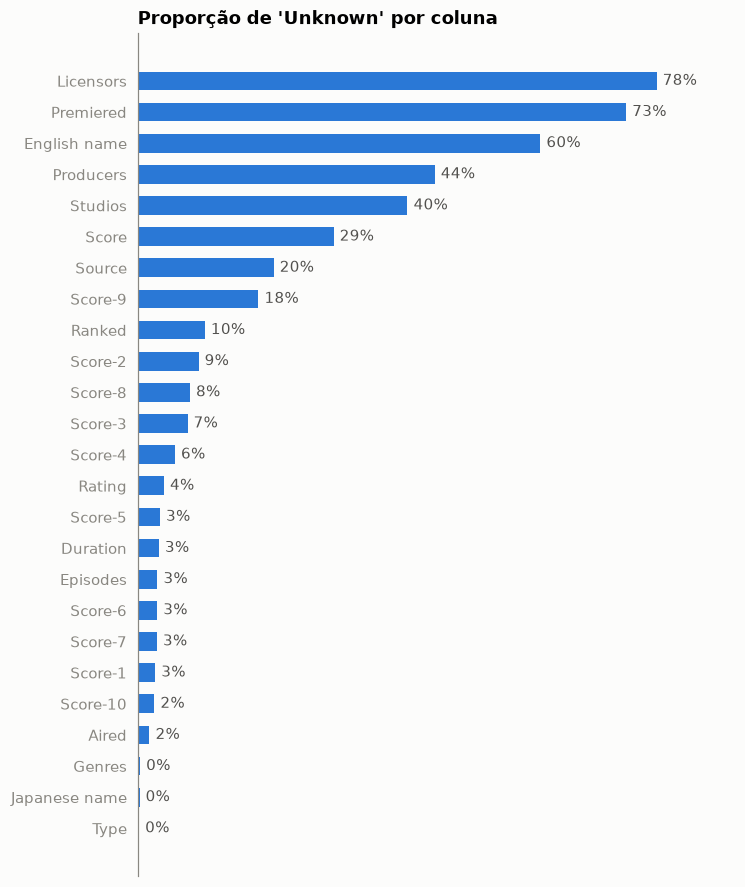

In [3]:
desconhecidos = (animes == "Unknown").mean().loc[lambda s: s > 0]
barras_horizontais(desconhecidos, "Proporção de 'Unknown' por coluna", formato="{:.0%}");

`Premiered`, `Licensors`, `Producers` e `English name` têm ausentes demais para servir de variável.
`Studios` também tem muitos, mas os estúdios conhecidos ajudam a separar estilos, então ficam só os mais frequentes.

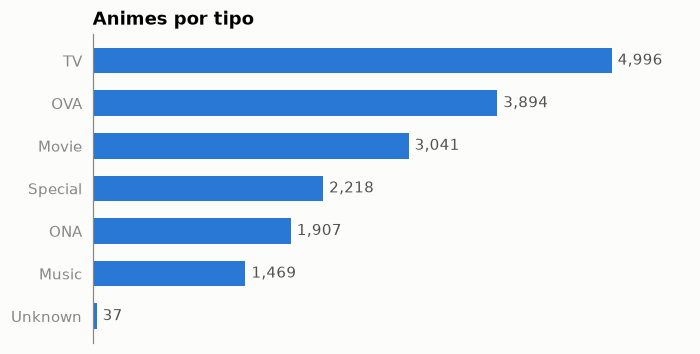

In [4]:
barras_horizontais(animes["Type"].value_counts(), "Animes por tipo");

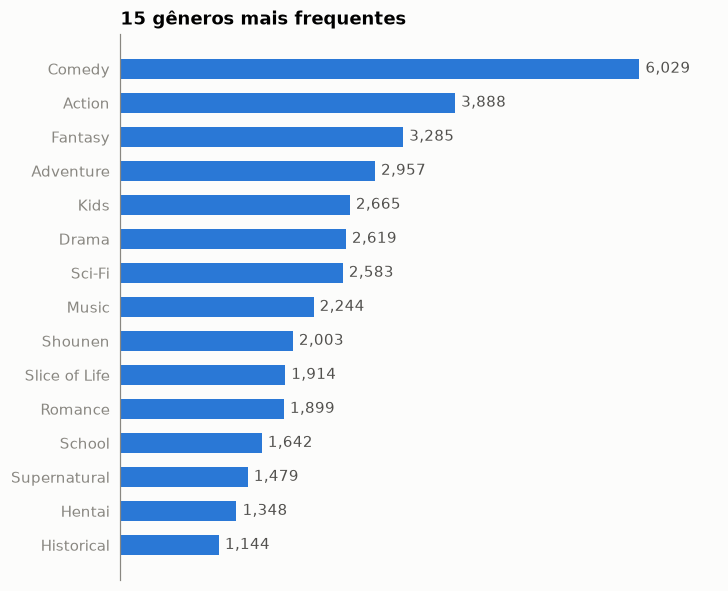

In [5]:
generos = animes["Genres"].str.split(", ").explode().value_counts()
barras_horizontais(generos.head(15), "15 gêneros mais frequentes");

### Viés de popularidade

Várias colunas medem a mesma coisa: quanta gente viu o anime.
Se todas entrarem no K-means, a popularidade domina os clusters.

In [6]:
colunas_popularidade = ["Popularity", "Members", "Favorites", "Watching", "Completed", "Dropped", "Plan to Watch"]
correlacao = (
    animes[colunas_popularidade]
    .assign(Score=pd.to_numeric(animes["Score"], errors="coerce"), Ranked=pd.to_numeric(animes["Ranked"], errors="coerce"))
    .corr(method="spearman")
)
correlacao["Popularity"].round(2).to_frame("Correlação de Spearman com Popularity")

,Correlação de Spearman com Popularity
Popularity,1.00
Members,-1.00
Favorites,-0.91
Watching,-0.92
Completed,-0.91
Dropped,-0.86
Plan to Watch,-0.98
Score,-0.73
Ranked,0.86


Tudo é fortemente correlacionado com `Popularity` (o sinal negativo é porque `Popularity` é uma posição: 1 = mais popular).
Como na monografia, fica **apenas `Popularity`** e saem ranking, pontuações, membros, favoritos etc.

### Filtro de conteúdo

Animes classificados como `Rx - Hentai` saem da base: o resultado final é um app em que o usuário escolhe entre "personas", e não faz sentido ter uma delas de conteúdo adulto.

In [7]:
adulto = animes["Rating"].eq("Rx - Hentai") | animes["Genres"].str.contains("Hentai")
animes = animes[~adulto]
print(f"{adulto.sum()} animes removidos, restam {len(animes)}")

1348 animes removidos, restam 16214


## 2. Base de avaliações

In [8]:
avaliacoes = pd.read_csv(
    DADOS_AVALIACOES, dtype={"user_id": "int32", "anime_id": "int32", "rating": "int8"}
)
print(f"{len(avaliacoes):,} avaliações | {avaliacoes['user_id'].nunique():,} usuários | {avaliacoes['anime_id'].nunique():,} animes")

57,633,278 avaliações | 310,059 usuários | 16,872 animes


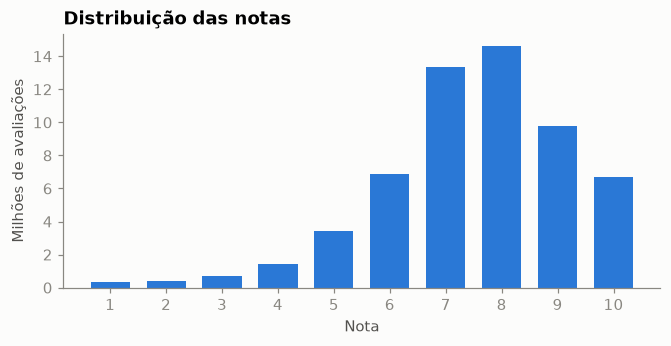

In [9]:
notas = avaliacoes["rating"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(notas.index.astype(str), notas.values / 1e6, color=AZUL, width=0.7)
ax.set_title("Distribuição das notas")
ax.set_xlabel("Nota")
ax.set_ylabel("Milhões de avaliações");

As notas se concentram entre 7 e 9: quem não gosta de um anime normalmente nem termina, então não avalia.

In [10]:
avaliacoes.groupby("user_id").size().describe().round(1).to_frame("Avaliações por usuário")

,Avaliações por usuário
count,310059.0
mean,185.9
std,255.3
min,1.0
25%,43.0
50%,113.0
75%,238.0
max,15455.0


### Amostragem

São 57 milhões de avaliações, e o KNN por força bruta compara o usuário novo com **todos** os outros.
Para caber em memória e responder rápido no app:

1. ficam só usuários com pelo menos 50 avaliações (perfis com informação suficiente);
2. desses, uma amostra aleatória de 20 mil usuários;
3. ficam só animes com pelo menos 50 avaliações dentro da amostra.

In [11]:
avaliacoes = avaliacoes[avaliacoes["anime_id"].isin(animes["MAL_ID"])]

por_usuario = avaliacoes.groupby("user_id").size()
usuarios_validos = por_usuario[por_usuario >= MIN_AVALIACOES_USUARIO].index.to_numpy()
amostra = np.random.default_rng(RANDOM_STATE).choice(usuarios_validos, N_USUARIOS, replace=False)
avaliacoes = avaliacoes[avaliacoes["user_id"].isin(amostra)]

por_anime = avaliacoes.groupby("anime_id").size()
avaliacoes = avaliacoes[avaliacoes["anime_id"].isin(por_anime[por_anime >= MIN_AVALIACOES_ANIME].index)]

print(f"{len(avaliacoes):,} avaliações | {avaliacoes['user_id'].nunique():,} usuários | {avaliacoes['anime_id'].nunique():,} animes")

4,871,707 avaliações | 20,000 usuários | 6,166 animes


## 3. Tratamento dos animes

Os dois modelos usam o mesmo conjunto de animes: os que sobraram na amostra de avaliações.

In [12]:
sinopses = pd.read_csv(DADOS_SINOPSES, usecols=["MAL_ID", "sypnopsis"]).rename(columns={"sypnopsis": "Sinopse"})

animes = (
    animes[animes["MAL_ID"].isin(avaliacoes["anime_id"])]
    .merge(sinopses, on="MAL_ID", how="left")
    .sort_values("MAL_ID")
    .reset_index(drop=True)
)
animes["Score"] = pd.to_numeric(animes["Score"], errors="coerce")
animes["Ano"] = extrair_ano(animes["Aired"])
animes["Faixa de ano"] = faixa_de_ano(animes["Ano"])
animes["Tamanho"] = tamanho(animes["Episodes"])
animes["Avaliações na amostra"] = animes["MAL_ID"].map(avaliacoes.groupby("anime_id").size())

animes = animes[
    ["MAL_ID", "Name", "English name", "Score", "Genres", "Type", "Episodes", "Studios", "Source",
     "Rating", "Popularity", "Ano", "Faixa de ano", "Tamanho", "Avaliações na amostra", "Sinopse"]
]
animes.head(3)

,MAL_ID,Name,English name,Score,Genres,Type,Episodes,Studios,Source,Rating,Popularity,Ano,Faixa de ano,Tamanho,Avaliações na amostra,Sinopse
0,1,Cowboy Bebop,Cowboy Bebop,8.78,"Action, Adventure, Comedy, Drama, Sci-Fi, Space",TV,26,Sunrise,Original,R - 17+ (violence & profanity),39,1998.0,Até 2000,14-26 episódios,6577,"In the year 2071, humanity has colonized sever..."
1,5,Cowboy Bebop: Tengoku no Tobira,Cowboy Bebop:The Movie,8.39,"Action, Drama, Mystery, Sci-Fi, Space",Movie,1,Bones,Original,R - 17+ (violence & profanity),518,2001.0,2000-2010,1 episódio,2873,"other day, another bounty—such is the life of ..."
2,6,Trigun,Trigun,8.24,"Action, Sci-Fi, Adventure, Comedy, Drama, Shounen",TV,26,Madhouse,Manga,PG-13 - Teens 13 or older,201,1998.0,Até 2000,14-26 episódios,3918,"Vash the Stampede is the man with a $$60,000,0..."


### Variáveis da clusterização

Variáveis *dummy* para gênero, estúdio (os 20 mais frequentes), tipo, fonte, classificação etária, faixa de ano e tamanho, mais a `Popularity`.

In [13]:
features = montar_features(animes)
print(features.shape)
features.sum().drop("Popularity").sort_values(ascending=False).head(10).to_frame("Animes com a característica")

(6166, 96)


,Animes com a característica
Classificação: PG-13 - Teens 13 or older,3688
Gênero: Comedy,2907
Tamanho: 2-13 episódios,2819
Tipo: TV,2738
Fonte: Manga,2300
Tamanho: 1 episódio,2257
Gênero: Action,2157
Ano: 2000-2010,1996
Ano: 2010-2015,1722
Ano: 2015-2030,1525


## 4. Matriz usuário × anime

Cada linha é um usuário, cada coluna um anime (na mesma ordem de `animes`), e o valor é a nota. Zero significa "não avaliou".
Como quase tudo é zero, a matriz é guardada em formato esparso.

In [14]:
linhas = pd.factorize(avaliacoes["user_id"], sort=True)[0]
colunas = pd.Index(animes["MAL_ID"]).get_indexer(avaliacoes["anime_id"])
matriz = sparse.csr_matrix(
    (avaliacoes["rating"].to_numpy(dtype=np.float32), (linhas, colunas)),
    shape=(linhas.max() + 1, len(animes)),
)
print(matriz.shape, f"| {matriz.nnz / np.prod(matriz.shape):.1%} das células preenchidas")

(20000, 6166) | 4.0% das células preenchidas


## 5. Salvando

In [15]:
animes.to_parquet(ANIMES_TRATADOS, index=False)
features.to_parquet(ANIMES_FEATURES, index=False)
dump(matriz, MATRIZ_USUARIO_ANIME, compress=3);